In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data' / 'news_article_dataset.json').exists())
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))


# Exploratory data analysis

I use the [AllSides-based dataset on Kaggle](https://www.kaggle.com/datasets/articoder/news-dataset-for-news-bias-analysis) to examine how the articles are distributed across position labels, topics, sources, and dates. This notebook also prepares article-level rows for the plots below.


## What the source file contains

Each line of the JSON file is a news roundup. A roundup may include separate left, center, and right article versions, so one source record can produce several article rows.


## Data preparation

I first read the roundup records, reshape the three article fields, and check incomplete or duplicated rows. I then parse the dates before plotting trends over time.


## Setup

The imports cover tables, date handling, text utilities, and plots. Any NLTK downloads in the next cell are needed for text analysis later in the notebook.


In [1]:
# ============================================
# Required installations (uncomment and run):
# !pip install pandas numpy matplotlib seaborn nltk tabulate fuzzywuzzy python-Levenshtein
#! pip install python-Levenshtein
# ============================================

# Suppress non-critical warnings
import warnings
warnings.filterwarnings("ignore")

# -- Data Manipulation and Analysis --
import pandas as pd
import numpy as np

# -- Visualization --
import matplotlib.pyplot as plt
import seaborn as sns

# -- Text Processing and NLP --
import re
from collections import Counter
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources if not already installed
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')

# -- Table Formatting & String Matching --
from tabulate import tabulate
from fuzzywuzzy import process



[nltk_data] Downloading package punkt to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Load the source data

The local file is JSON lines, with one roundup record per line. Reading it directly avoids depending on an intermediate TSV file that is not part of this project.


The original records group coverage of the same roundup under left, center, and right keys. I treat each available version as a separate article and keep its position label.


For each article I keep the title, body text, topic, date, position, and source extracted from its URL. This produces a table suitable for missing-value checks and plots.


In [2]:
# Load the dataset while ignoring the first unnamed column
df = pd.read_json(DATA_DIR / 'news_article_dataset.json', lines=True)

# Display dataset shape
print(f"Dataset Shape: {df.shape}")

Dataset Shape: (8478, 14)


In [3]:
# first 5 rows of the dataset
df.head()

,Title of Headline Roundup,description,Topics,Date,url_story,left_story_title,center_story_title,right_story_title,right_story_url,right_story_text,center_story_url,center_story_text,left_story_url,left_story_text
3513,Romney in London,NaN,Elections,2012-07-26,/story/romney-london,Romney's Olympics false start,Shaky Start for Romney Overseas Trip,Romney causes London stir over Olympic readine...,http://politics.blogs.foxnews.com/2012/07/26/r...,"The Brits, taking a break from beating up on t...",http://online.wsj.com/article/SB10000872396390...,Mitt Romney launched an overseas tour Thursday...,http://politicalticker.blogs.cnn.com/2012/07/2...,Mitt Romney told British leaders he hopes to t...
3512,Romney's Overseas Trip,NaN,Elections,2012-08-01,/story/romneys-overseas-trip,Was Romney's trip 'a great success' or gaffe-f...,Romney's Overseas Trip Produces Hits and Misses,RomneyÃ¢â‚¬â„¢s trip a bumpy ride,http://www.washingtontimes.com/news/2012/jul/3...,Under mounting pressure to be more open on for...,http://online.wsj.com/article/SB10000872396390...,"WARSAWâ€”With a speech lauding Poland as a ""de...",http://www.cnn.com/2012/07/31/politics/romney-...,OPINION\nWarsaw (CNN) -- In the estimation of ...
3511,Biden Comment Controversy,NaN,Elections,2012-08-16,/story/biden-comment-controversy,Mission Impossible: Managing Joe Biden,Campaign Trail: Biden's Comment About 'Chains'...,Ryan takes on Obama campaign over Biden 'chain...,http://www.foxnews.com/politics/2012/08/15/oba...,Paul Ryan is taking on the Obama campaign dire...,http://www.npr.org/blogs/thetwo-way/2012/08/15...,By telling a racially mixed audience in Virgin...,http://www.politico.com/news/stories/0812/7977...,The most emotionally powerful minute of Joe Bi...
3510,Romney Taxes,NaN,Elections,2012-08-17,/story/romney-taxes,Obama Campaign Wants Romney To Release 5 Years...,Romney Says He Paid A Tax Rate Of At Least 13 ...,Romney campaign doesn't bite on Obama tax retu...,http://www.foxnews.com/politics/2012/08/17/oba...,The Obama campaign made an unusual offer to Mi...,http://www.npr.org/blogs/itsallpolitics/2012/0...,Republican presidential candidate Mitt Romney ...,http://www.huffingtonpost.com/2012/08/17/obama...,With the spotlight back on Mitt Romney's tax r...
3509,Skinnydipping Congressman,NaN,US Congress,2012-08-20,/story/skinnydipping-congressman,"Exclusive: FBI probed GOP trip with drinking, ...",Congressman Who Took Nude Dip In Sea Of Galile...,Account of overseas skinny-dipping fuels clari...,http://www.foxnews.com/politics/2012/08/20/rep...,A bizarre report about Republican congressmen ...,http://www.npr.org/blogs/thetwo-way/2012/08/20...,"Saying he apologizes for ""any embarrassment I ...",http://www.politico.com/news/stories/0812/7986...,The FBI probed a late-night swim in the Sea of...


In [4]:
# Print the sample using tabulate for a nice text-based table
print(tabulate(df.head(5), headers='keys', tablefmt='psql'))

+------+-----------------------------+---------------+-------------+------------+----------------------------------+----------------------------------------------------------------+-------------------------------------------------------------------+------------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------

## Reshape the articles

The function below loops through each roundup and each position. It extracts the matching title, text, and URL, then appends one row for that article. The resulting table is saved to `outputs/` for inspection.


In [5]:
import pandas as pd
from urllib.parse import urlparse

def extract_source(url):
    """
    Extract the source name from a URL by parsing its domain.
    
    Parameters:
    url (str): The URL of the news article.

    Returns:
    str: The extracted source name (e.g., 'cnn' from 'cnn.com'), or None if extraction fails.
    """
    try:
        parsed = urlparse(url)
        domain = parsed.netloc
        if domain.startswith("www."):
            domain = domain[4:]  # Remove 'www.'
        return domain.split('.')[0]  # Extract the main domain name
    except Exception:
        return None  # Return None if URL parsing fails

def get_data_df(df):
    """
    Convert the dataset into a long-form DataFrame by extracting key fields.
    
    Parameters:
    df (pd.DataFrame): The original dataset containing multiple perspectives (Center, Left, Right).

    Returns:
    pd.DataFrame: A long-form DataFrame where each row represents a single story version.
    """
    output_rows = []

    # Correct column mappings based on actual dataset
    title_key = "story_title"
    text_key = "story_text"
    url_key = "story_url"
    topic_key = "Topics"
    date_key = "Date"

    # Iterate over each row in the dataset
    for _, row in df.iterrows():
        for position in ['left', 'center', 'right']:  # Extract details for each perspective
            title_col = f"{position}_{title_key}"
            text_col = f"{position}_{text_key}"
            url_col = f"{position}_{url_key}"

            # Ensure these columns exist
            if title_col not in df.columns or text_col not in df.columns or url_col not in df.columns:
                print(f"Skipping row due to missing columns: {title_col}, {text_col}, {url_col}")
                continue  # Skip if expected columns are missing

            try:
                title = str(row[title_col]).lower()
                text = str(row[text_col]).lower()
                link = str(row[url_col]).lower()
                topic = str(row[topic_key]).lower()
                date = row[date_key]
                source = extract_source(link)

                output_rows.append({
                    "title": title,
                    "topic": topic,
                    "text": text,
                    "position": position,
                    "source": source,
                    "date": date
                })
            except Exception as e:
                print(f"Error processing row: {e}")
                continue  # Skip problematic rows

    if not output_rows:
        print("No valid rows were processed.")
    
    return pd.DataFrame(output_rows)

# Convert dataset into long-form
df = get_data_df(df)

# Save the structured DataFrame as CSV and PKL
if not df.empty:
    df.to_csv(OUTPUT_DIR / 'Data_restructured.csv', index=False)
    df.to_pickle(OUTPUT_DIR / 'Data_restructured.pkl')
    print("Data successfully saved.")
else:
    print("No data to save.")



Data successfully saved.


In [6]:
# Print the sample using tabulate for a nice text-based table
print(tabulate(df.head(5), headers='keys', tablefmt='psql'))

+----+---------------------------------------------------------------+-----------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------+-----------------+------------+
|    | title                                                         | topic     | text                                                                                                                                                                                                                                                                                       | position   | source          | date       |
|----+---------------------------------------------------------------+-----------+----------------------------------------------------------------------------------------------

In [7]:
# Display dataset shape
print(f"Dataset Shape: {df.shape}")

Dataset Shape: (25434, 6)


## Missing values

An empty title, article body, or source makes a row less useful for this analysis. I count missing values and placeholder strings before filtering those rows.


In [8]:
# Define common missing value indicators
missing_values = ["nan", "n/a", "null", "none", "missing", "?", "-", ""]

# Standard missing count (NaN values)
total_missing = df.isnull().sum()

# Count other missing indicators by applying to each column
for missing_value in missing_values:
    total_missing += df.apply(lambda col: (col.astype(str).str.strip() == missing_value).sum() + col.astype(str).isnull().sum() + col.astype(str).isna().sum())

# Creating the summary DataFrame
summary_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Total Count': len(df),
    'Total Missing Count': total_missing,
    'Missing Percentage': (100 * total_missing / len(df)).round(2)
})

# Print the summary table
print("Dataset Summary:")
print(summary_df.sort_values('Missing Percentage', ascending=False))

Dataset Summary:
         Data Type  Total Count  Total Missing Count  Missing Percentage
text        object        25434                  929                3.65
title       object        25434                  911                3.58
source      object        25434                  911                3.58
topic       object        25434                    0                0.00
position    object        25434                    0                0.00
date        object        25434                    0                0.00


The summary includes both true nulls and common text placeholders such as `nan` or `n/a`. The next step removes incomplete rows using the title, text, and source columns; the saved count should be read as a result of this specific run.


In [9]:
# Define common missing value indicators
missing_values = ["nan", "n/a", "null", "none", "missing", "?", "-", ""]

rows_before_filtering = len(df)

# Drop rows where "text", "title", or "source" is either NaN or contains missing value indicators
df = df[~(
    df['text'].isna() | df['title'].isna() | df['source'].isna() | 
    df['text'].astype(str).str.strip().isin(missing_values) | 
    df['title'].astype(str).str.strip().isin(missing_values) | 
    df['source'].astype(str).str.strip().isin(missing_values)
)]

# Print the updated shape
print(f"Rows before filtering: {rows_before_filtering}")  # Size before removing incomplete rows
print(f"After dropping missing values from 'text', 'title', and 'source': {df.shape}")

# Save the cleaned dataset
df.to_csv(OUTPUT_DIR / 'Data_Cleaned.csv', index=False)
df.to_pickle(OUTPUT_DIR / 'Data_Cleaned.pkl')

print("Cleaned dataset saved successfully!")

Original dataset size: 25434
After dropping missing values from 'text', 'title', and 'source': (24505, 6)
Cleaned dataset saved successfully!


In [10]:
# Define common missing value indicators
missing_values = ["nan", "n/a", "null", "none", "missing", "?", "-", ""]

# Standard missing count (NaN values)
total_missing = df.isnull().sum()

# Count other missing indicators by applying to each column
for missing_value in missing_values:
    total_missing += df.apply(lambda col: (col.astype(str).str.strip() == missing_value).sum() + col.astype(str).isnull().sum() + col.astype(str).isna().sum())

# Creating the summary DataFrame
summary_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Total Count': len(df),
    'Total Missing Count': total_missing,
    'Missing Percentage': (100 * total_missing / len(df)).round(2)
})

# Print the summary table
print("Dataset Summary:")
print(summary_df.sort_values('Missing Percentage', ascending=False))

Dataset Summary:
         Data Type  Total Count  Total Missing Count  Missing Percentage
title       object        24505                    0                 0.0
topic       object        24505                    0                 0.0
text        object        24505                    0                 0.0
position    object        24505                    0                 0.0
source      object        24505                    0                 0.0
date        object        24505                    0                 0.0


## Exact duplicates

Two rows with the same title and body text do not add independent article content. I check exact matches on those two fields before making a cleaned copy.


In [11]:
import pandas as pd
from tabulate import tabulate

# Identify exact duplicate rows based only on "title" and "text" columns
duplicate_mask = df.duplicated(subset=["title", "text"], keep=False)
duplicates_df = df[duplicate_mask]

# Check if there are any duplicates
if duplicates_df.empty:
    print("No duplicates were found in the 'title' and 'text' columns, hence no need to drop anything.")
else:
    # Print the number of exact duplicate rows
    print(f"\nNumber of exact duplicate rows based on 'title' and 'text': {duplicates_df.shape[0]}")

    # Display all exact duplicate rows in a formatted table using tabulate
    print("\n=== Exact Duplicate Rows (Based on 'title' and 'text') ===")
    print(tabulate(duplicates_df, headers='keys', tablefmt='psql', showindex=False))


Number of exact duplicate rows based on 'title' and 'text': 10

=== Exact Duplicate Rows (Based on 'title' and 'text') ===
+--------------------------------------------------------------------------+------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------+----------------+------------+
| title                                                                    | topic      | text                                                                                                                                                                                                                  

In [12]:
# Drop rows where "title" and "text" are exactly the same
df = df.drop_duplicates(subset=["title", "text"], keep=False)

# Print the updated dataset shape
print(f"\nDataset size after dropping exact duplicate rows (based on 'title' and 'text'): {df.shape}")

# Save the cleaned dataset without duplicate title-text pairs
df.to_csv(OUTPUT_DIR / 'Data_Cleaned_No_Title_Text_Duplicates.csv', index=False)
df.to_pickle(OUTPUT_DIR / 'Data_Cleaned_No_Title_Text_Duplicates.pkl')

print("\nCleaned dataset saved successfully without exact title-text duplicates!")


Dataset size after dropping exact duplicate rows (based on 'title' and 'text'): (24495, 6)

Cleaned dataset saved successfully without exact title-text duplicates!


The duplicate check is deliberately narrow: it compares title and text, not topic or date. The following cell drops all rows in a repeated title-text group, so it removes both copies rather than keeping one.


## Publication dates

I check whether each date can be parsed, convert valid values to timestamps, and extract the year. This lets the later charts use a consistent date field.


In [13]:
# Define a function to check if a value is convertible to datetime
def is_convertible_to_datetime(x):
    try:
        pd.to_datetime(x)
        return True
    except Exception:
        return False

# Apply the function to the 'date' column
df['date_convertible'] = df['date'].apply(is_convertible_to_datetime)

# Count convertible and non-convertible entries
convertible_count = df['date_convertible'].sum()
non_convertible_count = (~df['date_convertible']).sum()

print(f"Convertible dates: {convertible_count}")
print(f"Non-convertible dates: {non_convertible_count}")

# Display unique values from 'date' that are non-convertible
problematic_values = df.loc[~df['date_convertible'], 'date'].unique()
print("\n=== Problematic 'date' Values ===")
print(problematic_values)

#  Now, let's check the different date formats among convertible entries

# Define a list of regex patterns along with their corresponding format labels
date_patterns = [
    # Numeric dates with different delimiters:
    (r'^\d{4}-\d{2}-\d{2}$', 'YYYY-MM-DD'),                   # 2016-09-20
    (r'^\d{4}/\d{2}/\d{2}$', 'YYYY/MM/DD'),                   # 2016/09/20
    (r'^\d{4}\.\d{2}\.\d{2}$', 'YYYY.MM.DD'),                   # 2016.09.20

    # Dates where day and month can be 1 or 2 digits and year can be 2 or 4 digits:
    (r'^\d{1,2}/\d{1,2}/\d{2,4}$', 'M/D/YY(YY)'),              # 7/23/17 or 07/23/2017
    (r'^\d{1,2}-\d{1,2}-\d{2,4}$', 'M-D-YY(YY)'),              # 7-23-17 or 07-23-2017
    (r'^\d{1,2}\.\d{1,2}\.\d{2,4}$', 'M.D.YY(YY)'),            # 7.23.17 or 07.23.2017

    # Dates with time components:
    (r'^\d{4}-\d{1,2}-\d{1,2}\s+\d{2}:\d{2}:\d{2}$', 'YYYY-M-D HH:MM:SS'),  # 2016-9-20 14:30:00
    (r'^\d{4}/\d{1,2}/\d{1,2}\s+\d{2}:\d{2}:\d{2}$', 'YYYY/M/D HH:MM:SS'),  # 2016/9/20 14:30:00

    # ISO8601 formats:
    (r'^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$', 'YYYY-MM-DDTHH:MM:SSZ'),            # 2016-09-20T14:30:00Z
    (r'^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}\.\d+Z$', 'YYYY-MM-DDTHH:MM:SS.sssZ'),    # 2016-09-20T14:30:00.123Z

    # Dates with month names:
    (r'^\d{1,2}\s+[A-Za-z]{3,9}\s+\d{4}$', 'D Month YYYY'),     # 20 September 2016 or 20 Sep 2016
    (r'^[A-Za-z]{3,9}\s+\d{1,2},\s+\d{4}$', 'Month D, YYYY'),    # September 20, 2016 or Sep 20, 2016
    (r'^\d{1,2}-[A-Za-z]{3}-\d{4}$', 'D-Month-YYYY'),            # 20-Sep-2016
    (r'^\d{1,2}\s+[A-Za-z]{3}\s+\d{4}$', 'D Month YYYY'),        # 20 Sep 2016

    # Year only:
    (r'^\d{4}$', 'YYYY')                                        # 2016
]

# Function to detect the date format based on the defined regex patterns
def detect_date_format(date_str):
    for pattern, label in date_patterns:
        if re.match(pattern, date_str):
            return label
    return 'unknown'

# For convertible dates, convert the values to strings
convertible_dates = df.loc[df['date_convertible'], 'date'].astype(str)

# Apply the function to detect date formats
detected_formats = convertible_dates.apply(detect_date_format)

# Get the count of each detected format
format_counts = detected_formats.value_counts()

print("\nDistinct date formats in convertible entries:")
print(format_counts)

Convertible dates: 24495
Non-convertible dates: 0

=== Problematic 'date' Values ===
[]

Distinct date formats in convertible entries:
date
YYYY-MM-DD    24495
Name: count, dtype: int64


In [14]:
# Convert 'date' column to datetime format using flexible inference
df['date'] = pd.to_datetime(df['date'], errors='raise')

# Extract year from the 'date' column and create a new 'year' column
df['year'] = df['date'].dt.year

# Print the minimum and maximum dates
print("Minimum date:", df['date'].min())
print("Maximum date:", df['date'].max())

# Print the minimum and maximum years
print("Minimum year:", df['year'].min())
print("Maximum year:", df['year'].max())

Minimum date: 2012-07-26 00:00:00
Maximum date: 2025-02-25 00:00:00
Minimum year: 2012
Maximum year: 2025


In [15]:
# Drop the temporary column used for conversion checks
df.drop(columns=['date_convertible'], inplace=True)

The source dates run from July 2012 to February 2025. The year plots show when articles in this collection were published, not the total volume of news in those years.


In [16]:
# Define common missing value indicators
missing_values = ["NA", "N/A", "null", "NULL", "None", "none", "missing", "?", "-", ""]

# Standard missing count (NaN values)
total_missing = df.isnull().sum()

# Count other missing indicators by applying to each column
for missing_value in missing_values:
    total_missing += df.apply(lambda col: (col.astype(str).str.strip() == missing_value).sum())

# Creating the summary DataFrame
summary_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Total Count': len(df),
    'Total Missing Count': total_missing,
    'Missing Percentage': (100 * total_missing / len(df)).round(2)
})

# Print the summary table
print("Dataset Summary:")
print(summary_df.sort_values('Missing Percentage', ascending=False))

Dataset Summary:
               Data Type  Total Count  Total Missing Count  Missing Percentage
title             object        24495                    0                 0.0
topic             object        24495                    0                 0.0
text              object        24495                    0                 0.0
position          object        24495                    0                 0.0
source            object        24495                    0                 0.0
date      datetime64[ns]        24495                    0                 0.0
year               int32        24495                    0                 0.0


## Exploratory plots

The plots compare article counts by topic, source, position, and year. I use counts to identify uneven coverage before interpreting the model results.


### Article, topic, and source counts

The reshaped data contains 24,523 article rows from 8,478 roundup records. It has 126 topic labels and 414 source names extracted from URLs. These counts describe this collection; a few common topics contribute many more articles than the rest.


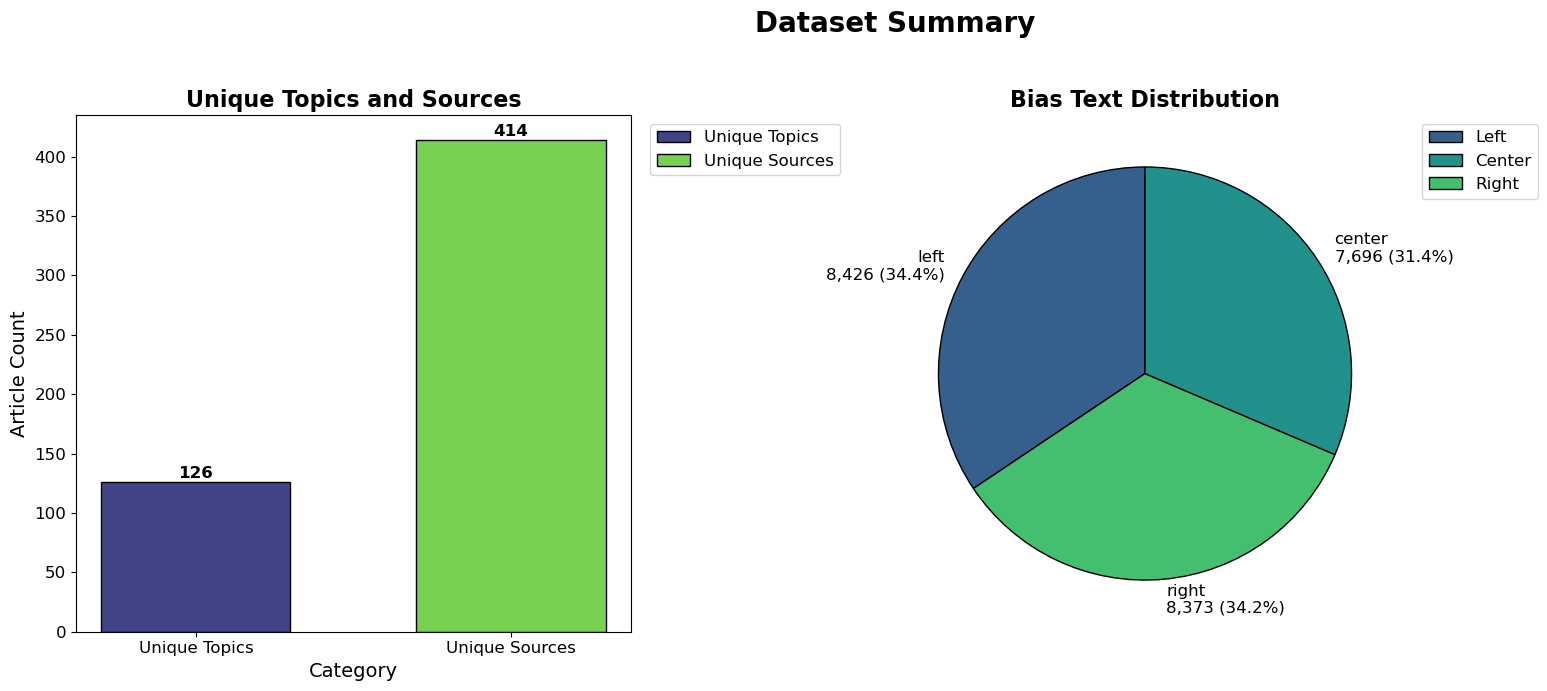

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# --- Data Preparation ---

# Count unique topics and sources
unique_topics = df['topic'].nunique()
unique_sources = df['source'].nunique()

# Create a DataFrame for unique topics and sources
topics_sources_data = pd.DataFrame({
    'Category': ['Unique Topics', 'Unique Sources'],
    'Count': [unique_topics, unique_sources]
})

# Count bias text distribution and calculate percentages
bias_counts = df['position'].value_counts().reset_index()
bias_counts.columns = ['Bias', 'Count']
bias_counts['Percentage'] = (bias_counts['Count'] / len(df)) * 100

# --- Define a Professional Color Palette ---
viridis_palette = sns.color_palette("viridis", as_cmap=True)

# Assign viridis colors to topics and sources
color_topics = viridis_palette(0.2)  # Color for Topics
color_sources = viridis_palette(0.8)  # Color for Sources

# Define a color mapping for bias categories using viridis colors
bias_palette = {
    'left': viridis_palette(0.3),    # Color for left
    'center': viridis_palette(0.5),  # Color for center
    'right': viridis_palette(0.7)    # Color for right
}

# Map bias colors; default to neutral gray if bias not found
bias_counts['Color'] = bias_counts['Bias'].str.lower().map(bias_palette).fillna('#A9A9A9')

# --- Plotting ---
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Subplot 1: Unique Topics and Sources (Bar Chart)
axs[0].bar(topics_sources_data['Category'], topics_sources_data['Count'],
           color=[color_topics, color_sources], edgecolor='black', width=0.6)
axs[0].set_title('Unique Topics and Sources', fontsize=16, fontweight='bold')
axs[0].set_xlabel('Category', fontsize=14)
axs[0].set_ylabel('Article Count', fontsize=14)
axs[0].tick_params(axis='both', labelsize=12)

# Add a box around the plot
axs[0].spines['top'].set_visible(True)
axs[0].spines['right'].set_visible(True)
axs[0].spines['left'].set_visible(True)
axs[0].spines['bottom'].set_visible(True)
axs[0].spines['top'].set_color('black')
axs[0].spines['right'].set_color('black')
axs[0].spines['left'].set_color('black')
axs[0].spines['bottom'].set_color('black')

# Annotate bar chart with counts
for idx, row in topics_sources_data.iterrows():
    axs[0].text(idx, row['Count'] + 1, f"{row['Count']}", ha='center', va='bottom',
                fontweight='bold', fontsize=12)

# Legend for subplot 1
legend_ts = [
    mpatches.Patch(facecolor=color_topics, edgecolor='black', label='Unique Topics'),
    mpatches.Patch(facecolor=color_sources, edgecolor='black', label='Unique Sources')
]
axs[0].legend(handles=legend_ts, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=12)

# Subplot 2: Bias Text Distribution as a Pie Chart
# Create labels that combine bias, count, and percentage with commas
pie_labels = [f"{row['Bias']}\n{int(row['Count']):,} ({row['Percentage']:.1f}%)" 
              for _, row in bias_counts.iterrows()]
axs[1].pie(bias_counts['Count'], labels=pie_labels, colors=bias_counts['Color'], 
           startangle=90, wedgeprops={'edgecolor': 'black'}, textprops={'fontsize': 12})
axs[1].set_title('Bias Text Distribution', fontsize=16, fontweight='bold')

# Legend for subplot 2
legend_bias = [mpatches.Patch(facecolor=color, edgecolor='black', label=bias.capitalize()) 
               for bias, color in bias_palette.items()]
axs[1].legend(handles=legend_bias, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=12)

# Overall Figure Title and Layout Adjustments
fig.suptitle('Dataset Summary', fontsize=20, fontweight='bold')
fig.tight_layout(rect=[0, 0, 0.85, 0.95])
plt.show()


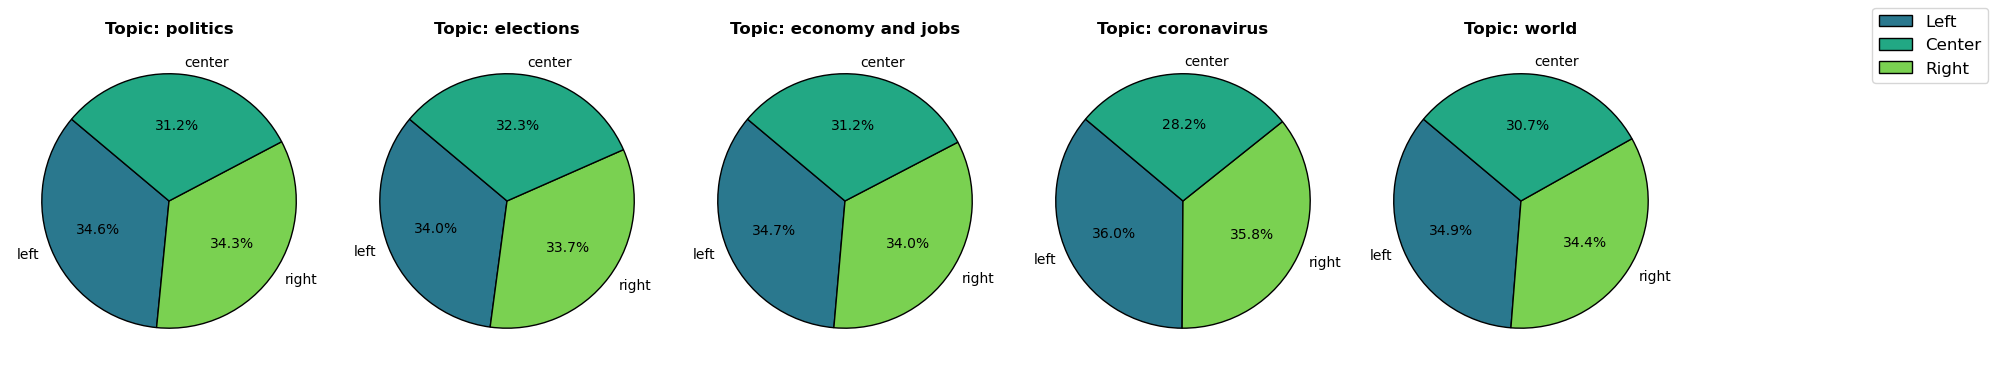

In [78]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Identify the top 5 topics by article count
top_5_topics = df['topic'].value_counts().head(5).index.tolist()

# Define a color mapping for bias categories using Viridis colors
bias_palette = {
    'left': sns.color_palette("viridis", 4)[1],    # Color for left
    'center': sns.color_palette("viridis", 4)[2],  # Color for center
    'right': sns.color_palette("viridis", 4)[3]    # Color for right
}

# Create a figure with 1 row and 5 columns for the top 5 topics
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(20, 4))

# Loop through each topic and plot its bias distribution as a pie chart
for i, topic in enumerate(top_5_topics):
    # Filter the dataset for the current topic
    df_topic = df[df['topic'] == topic]
    # Count the distribution of bias labels for this topic
    bias_counts = df_topic['position'].value_counts().reset_index()
    bias_counts.columns = ['Bias', 'Count']
    # Map the bias labels to colors using our defined palette
    bias_counts['Color'] = bias_counts['Bias'].str.lower().map(bias_palette).fillna('#A9A9A9')
    
    # Plot a pie chart on the corresponding subplot
    axes[i].pie(
        bias_counts['Count'],
        labels=bias_counts['Bias'],
        colors=bias_counts['Color'],
        autopct='%1.1f%%',
        startangle=140,
        wedgeprops={'edgecolor': 'black'}
    )
    axes[i].set_title(f"Topic: {topic}", fontsize=12, fontweight='bold')

# Create a single common legend for all pie charts
legend_handles = [
    mpatches.Patch(facecolor=color, edgecolor='black', label=bias.capitalize()) 
    for bias, color in bias_palette.items()
]
fig.legend(handles=legend_handles, loc='upper right', fontsize=12)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

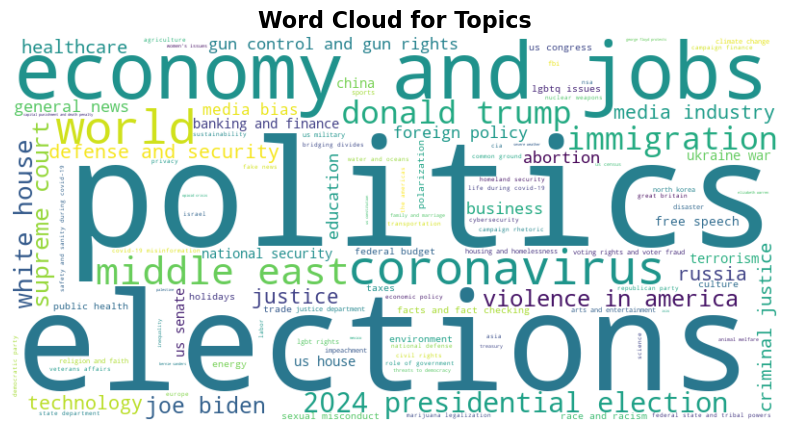

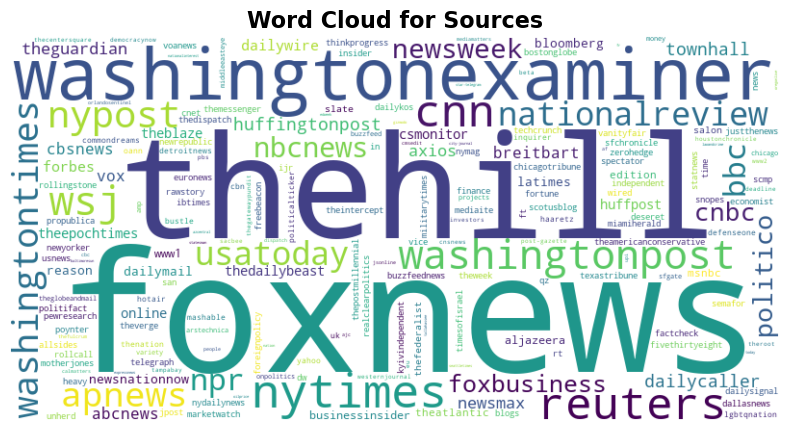

In [18]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_wordcloud(freq_dict, title):
    """
    Generates and displays a word cloud from a frequency dictionary.
    
    Parameters:
    - freq_dict: dict, frequency mapping of words to counts.
    - title: str, title for the word cloud plot.
    """
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis'
    ).generate_from_frequencies(freq_dict)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16, fontweight='bold')
    plt.show()

# Generate frequency dictionaries for topics and sources
topics_dict = df['topic'].value_counts().to_dict()
sources_dict = df['source'].value_counts().to_dict()

# Plot word clouds for topics and sources
plot_wordcloud(topics_dict, "Word Cloud for Topics")
plot_wordcloud(sources_dict, "Word Cloud for Sources")

## Topic word cloud

Each word represents a topic label, and its size reflects that label’s frequency in the cleaned rows. The plot is a quick view of common subjects; the count tables give the precise values.


In [19]:
# Group by source and collect all distinct position values
bias_categories_per_source = (
    df.groupby('source')['position']
      .apply(lambda x: set(x))  # Convert to a set of distinct bias categories
      .reset_index(name='bias_categories')
)

# Add a column for the count of distinct bias categories
bias_categories_per_source['distinct_bias_count'] = bias_categories_per_source['bias_categories'].apply(len)

# Filter for sources with more than one bias category
sources_multiple_bias = bias_categories_per_source[bias_categories_per_source['distinct_bias_count'] > 1]

print("Sources appearing in more than one bias category, with their categories:")
print(sources_multiple_bias)

Sources appearing in more than one bias category, with their categories:
                 source        bias_categories  distinct_bias_count
4               abcnews         {left, center}                    2
15             allsides  {right, left, center}                    3
21                  amp  {right, left, center}                    3
23               apnews         {left, center}                    2
24              archive         {left, center}                    2
..                  ...                    ...                  ...
395  washingtonexaminer        {right, center}                    2
396      washingtonpost  {right, left, center}                    3
397     washingtontimes          {right, left}                    2
402               wired         {left, center}                    2
404                 wsj  {right, left, center}                    3

[71 rows x 3 columns]


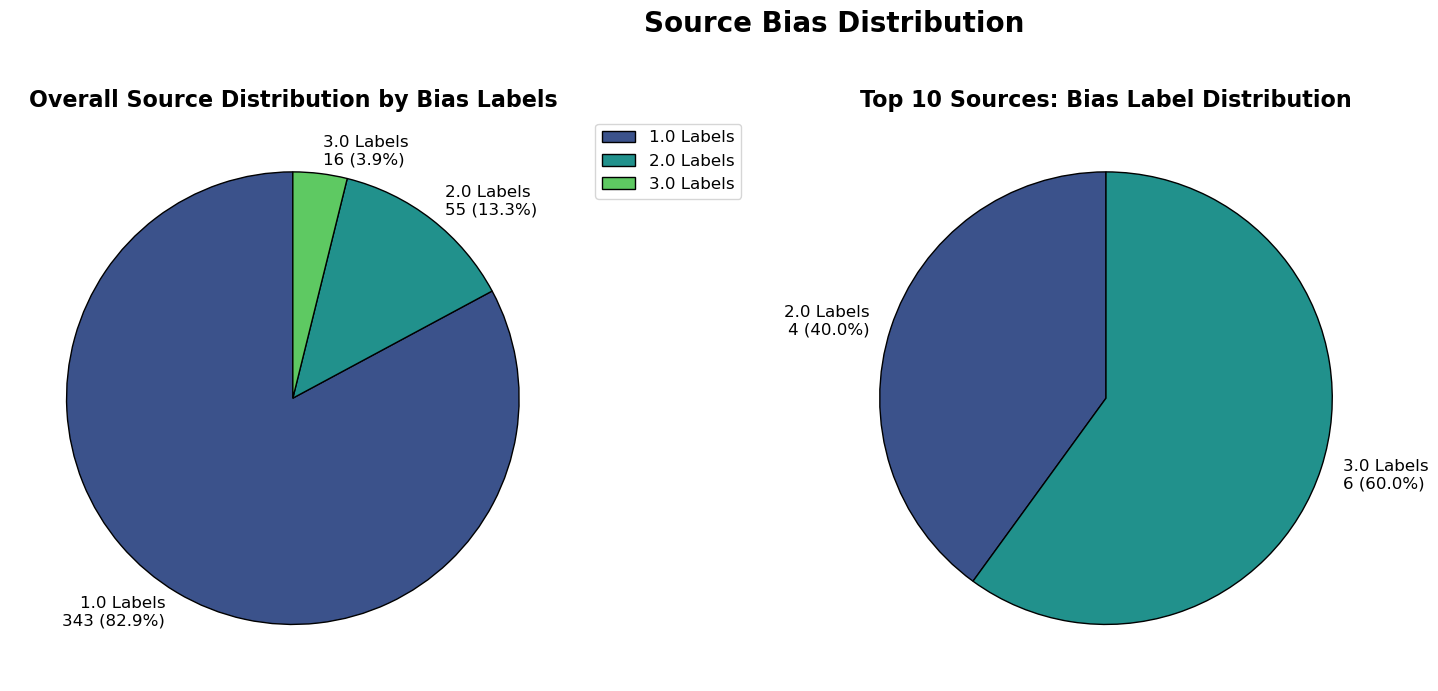

In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# --- Data Preparation ---

# Count the number of sources by distinct bias categories (for overall dataset)
bias_count_distribution = (
    bias_categories_per_source['distinct_bias_count']
    .value_counts()
    .sort_index()
    .reset_index()
)
bias_count_distribution.columns = ['Bias Labels Count', 'Source Count']
bias_count_distribution['Percentage'] = (
    bias_count_distribution['Source Count'] / len(bias_categories_per_source) * 100
).round(1)

# Count the number of sources by distinct bias categories (for top 10 sources)
top_10_sources_list = df['source'].value_counts().head(10).index.tolist()
bias_count_top_10 = bias_categories_per_source[bias_categories_per_source['source'].isin(top_10_sources_list)]
bias_count_top_10_distribution = (
    bias_count_top_10['distinct_bias_count']
    .value_counts()
    .sort_index()
    .reset_index()
)
bias_count_top_10_distribution.columns = ['Bias Labels Count', 'Source Count']
bias_count_top_10_distribution['Percentage'] = (
    bias_count_top_10_distribution['Source Count'] / len(bias_count_top_10) * 100
).round(1)

# Create a color palette for bias label counts
label_palette = sns.color_palette("viridis", len(bias_count_distribution))

# --- Plotting ---
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Subplot 1: Overall Bias Label Distribution
overall_labels = [
    f"{row['Bias Labels Count']} Labels\n{int(row['Source Count']):,} ({row['Percentage']}%)"
    for _, row in bias_count_distribution.iterrows()
]
axs[0].pie(
    bias_count_distribution['Source Count'],
    labels=overall_labels,
    colors=[label_palette[i] for i in range(len(bias_count_distribution))],
    startangle=90,
    wedgeprops={'edgecolor': 'black'},
    textprops={'fontsize': 12}
)
axs[0].set_title('Overall Source Distribution by Bias Labels', fontsize=16, fontweight='bold', loc='center')

# Subplot 2: Top 10 Sources Bias Label Distribution
top_10_labels = [
    f"{row['Bias Labels Count']} Labels\n{int(row['Source Count']):,} ({row['Percentage']}%)"
    for _, row in bias_count_top_10_distribution.iterrows()
]
axs[1].pie(
    bias_count_top_10_distribution['Source Count'],
    labels=top_10_labels,
    colors=[label_palette[i] for i in range(len(bias_count_top_10_distribution))],
    startangle=90,
    wedgeprops={'edgecolor': 'black'},
    textprops={'fontsize': 12}
)
axs[1].set_title('Top 10 Sources: Bias Label Distribution', fontsize=16, fontweight='bold', loc='center')

# Legends
legend_patches = [
    mpatches.Patch(facecolor=label_palette[i], edgecolor='black', label=f"{row['Bias Labels Count']} Labels")
    for i, row in bias_count_distribution.iterrows()
]
axs[0].legend(handles=legend_patches, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=12)

# Overall Figure Title and Layout Adjustments
fig.suptitle('Source Bias Distribution', fontsize=20, fontweight='bold', ha='center')
fig.tight_layout(rect=[0, 0, 0.85, 0.95])
plt.show()

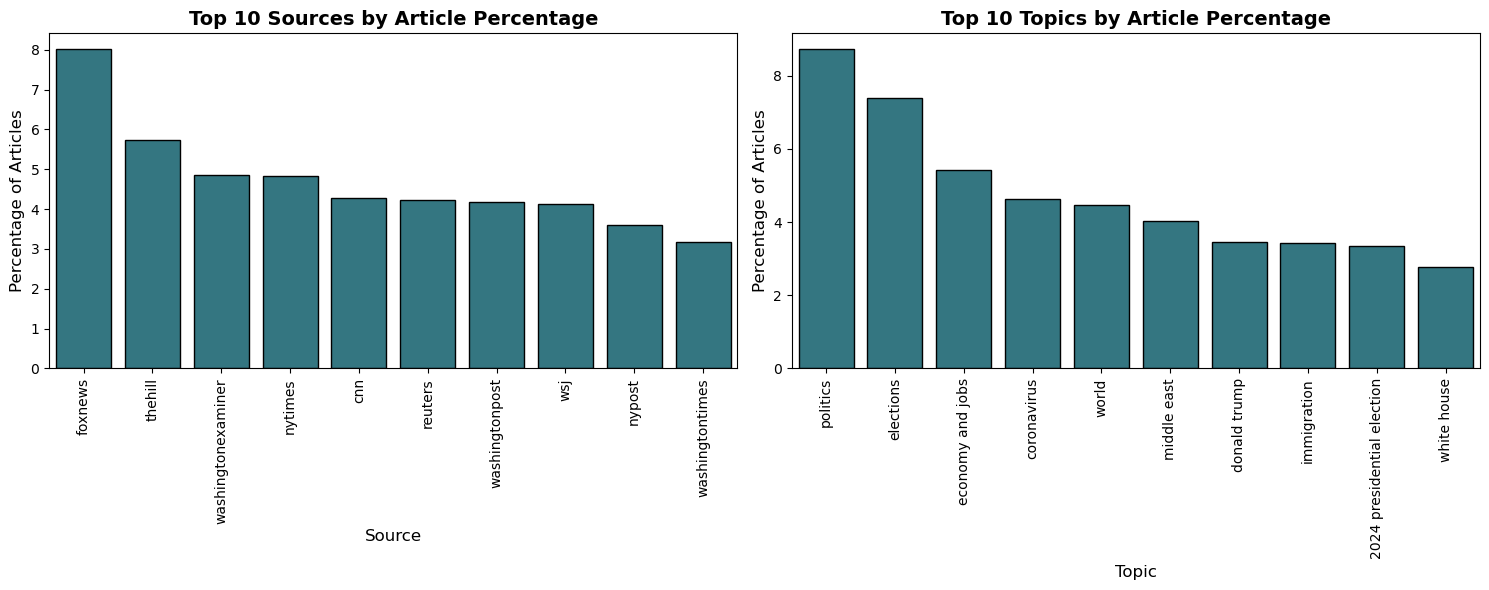

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data Preparation ---

# Check if the "topic" column exists
topic_col = 'topic' if 'topic' in df.columns else None  # Set to None if not found

# Define a function to calculate percentage within dataset
def calculate_percentage_no_bias(df, group_by_col):
    grouped_df = df[group_by_col].value_counts().reset_index()
    grouped_df.columns = [group_by_col, 'Count']
    grouped_df['Percentage'] = (grouped_df['Count'] / grouped_df['Count'].sum() * 100).round(2)
    return grouped_df

# Get top 10 sources by article count
top_10_sources = calculate_percentage_no_bias(df, 'source').head(10)

# Get top 10 topics by article count (Only if topic column exists)
top_10_topics = calculate_percentage_no_bias(df, topic_col).head(10) if topic_col else None

# Define a single color for bars
bar_color = sns.color_palette("viridis")[2]

# --- Plotting ---
fig, axes = plt.subplots(1, 2 if topic_col else 1, figsize=(15, 6))

# Subplot 1: Top 10 Sources by Article Percentage (Vertical Bar Chart)
sns.barplot(data=top_10_sources, x='source', y='Percentage', color=bar_color, edgecolor='black', ax=axes[0] if topic_col else axes)
axes[0 if topic_col else 0].set_title("Top 10 Sources by Article Percentage", fontsize=14, fontweight='bold')
axes[0 if topic_col else 0].set_xlabel("Source", fontsize=12)
axes[0 if topic_col else 0].set_ylabel("Percentage of Articles", fontsize=12)
axes[0 if topic_col else 0].tick_params(axis='x', rotation=90)

# Subplot 2: Top 10 Topics by Article Percentage (if applicable)
if topic_col:
    sns.barplot(data=top_10_topics, x=topic_col, y='Percentage', color=bar_color, edgecolor='black', ax=axes[1])
    axes[1].set_title("Top 10 Topics by Article Percentage", fontsize=14, fontweight='bold')
    axes[1].set_xlabel("Topic", fontsize=12)
    axes[1].set_ylabel("Percentage of Articles", fontsize=12)
    axes[1].tick_params(axis='x', rotation=90)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

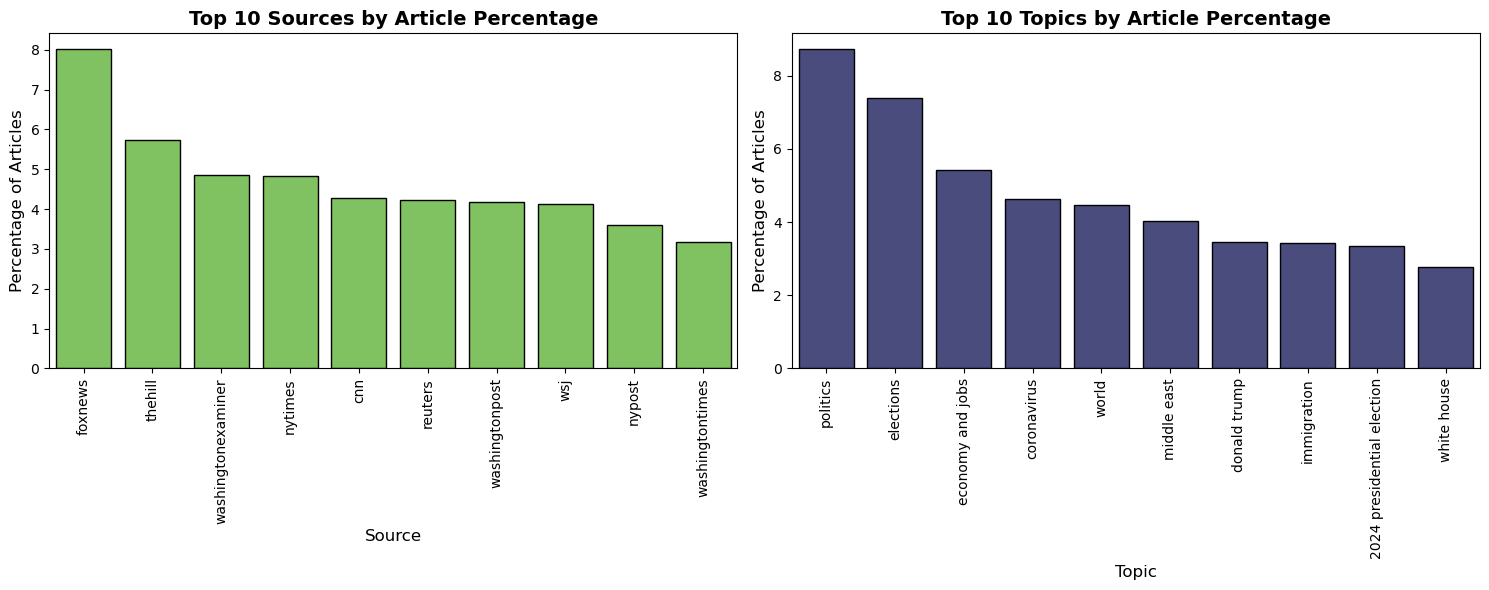

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data Preparation ---

# Check if the "topic" column exists
topic_col = 'topic' if 'topic' in df.columns else None  # Set to None if not found

# Define a function to calculate percentage within dataset
def calculate_percentage_no_bias(df, group_by_col):
    grouped_df = df[group_by_col].value_counts().reset_index()
    grouped_df.columns = [group_by_col, 'Count']
    grouped_df['Percentage'] = (grouped_df['Count'] / grouped_df['Count'].sum() * 100).round(2)
    return grouped_df

# Get top 10 sources by article count
top_10_sources = calculate_percentage_no_bias(df, 'source').head(10)

# Get top 10 topics by article count (Only if topic column exists)
top_10_topics = calculate_percentage_no_bias(df, topic_col).head(10) if topic_col else None

# Define colors
color_sources = (0.477504, 0.821444, 0.318195, 1.0)
color_topics = (0.253935, 0.265254, 0.529983, 1.0)

# --- Plotting ---
fig, axes = plt.subplots(1, 2 if topic_col else 1, figsize=(15, 6))

# Subplot 1: Top 10 Sources by Article Percentage (Vertical Bar Chart)
sns.barplot(data=top_10_sources, x='source', y='Percentage', color=color_sources, edgecolor='black', ax=axes[0] if topic_col else axes)
axes[0 if topic_col else 0].set_title("Top 10 Sources by Article Percentage", fontsize=14, fontweight='bold')
axes[0 if topic_col else 0].set_xlabel("Source", fontsize=12)
axes[0 if topic_col else 0].set_ylabel("Percentage of Articles", fontsize=12)
axes[0 if topic_col else 0].tick_params(axis='x', rotation=90)

# Subplot 2: Top 10 Topics by Article Percentage (if applicable)
if topic_col:
    sns.barplot(data=top_10_topics, x=topic_col, y='Percentage', color=color_topics, edgecolor='black', ax=axes[1])
    axes[1].set_title("Top 10 Topics by Article Percentage", fontsize=14, fontweight='bold')
    axes[1].set_xlabel("Topic", fontsize=12)
    axes[1].set_ylabel("Percentage of Articles", fontsize=12)
    axes[1].tick_params(axis='x', rotation=90)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

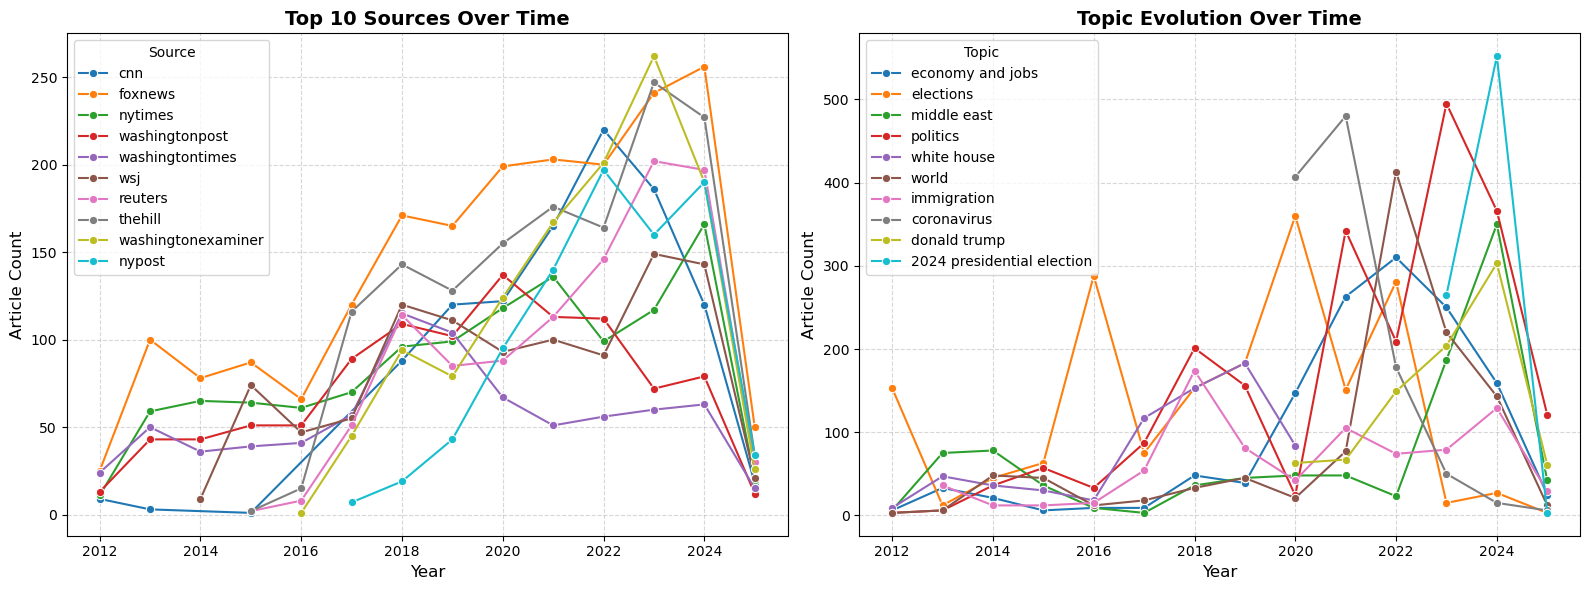

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data Preparation ---

# 1. Top 10 Sources Over Time (Line Plot)
# Get the top 10 sources by article count
top_10_sources_list = df['source'].value_counts().head(10).index.tolist()

# Filter dataset for only top 10 sources and group by 'year' and 'source'
df_top_sources_year = df[df['source'].isin(top_10_sources_list)]\
    .groupby(['year', 'source']).size().reset_index(name='Article Count')

# 2. Topic Evolution Over Time (Line Plot)
# Get the top 10 topics by article count
top_topics_list = df['topic'].value_counts().head(10).index.tolist()

# Filter dataset for only top topics and group by 'year' and 'topic'
df_topic_trend = df[df['topic'].isin(top_topics_list)]\
    .groupby(['year', 'topic']).size().reset_index(name='Article Count')

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graph 1: Top 10 Sources Over Time
sns.lineplot(data=df_top_sources_year, x='year', y='Article Count', hue='source', marker="o", ax=axes[0])
axes[0].set_title("Top 10 Sources Over Time", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Year", fontsize=12)
axes[0].set_ylabel("Article Count", fontsize=12)
axes[0].legend(title="Source", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Graph 2: Topic Evolution Over Time
sns.lineplot(data=df_topic_trend, x='year', y='Article Count', hue='topic', marker="o", ax=axes[1])
axes[1].set_title("Topic Evolution Over Time", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Year", fontsize=12)
axes[1].set_ylabel("Article Count", fontsize=12)
axes[1].legend(title="Topic", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

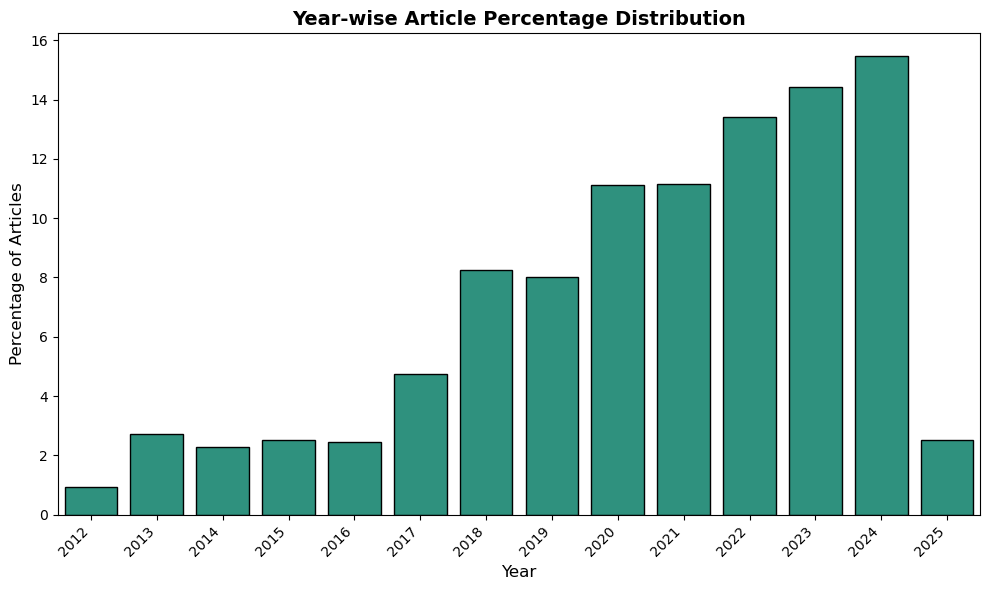

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Data Preparation ---
def calculate_percentage_no_bias(df, group_by_col):
    grouped_df = df[group_by_col].value_counts().reset_index()
    grouped_df.columns = [group_by_col, 'Count']
    grouped_df['Percentage'] = (grouped_df['Count'] / grouped_df['Count'].sum() * 100).round(2)
    return grouped_df

# Calculate year-wise distribution
year_distribution = calculate_percentage_no_bias(df, 'year')

# Define a color for the year bars (using a Viridis color from the palette)
color_year = sns.color_palette("viridis")[3]

# --- Plotting ---
plt.figure(figsize=(10, 6))
sns.barplot(data=year_distribution, x='year', y='Percentage', color=color_year, edgecolor='black')

# Add trend line
z = np.polyfit(year_distribution['year'], year_distribution['Percentage'], 1)
p = np.poly1d(z)
plt.plot(year_distribution['year'], p(year_distribution['year']), color='red', linestyle='--')

# Add labels to the bars
for index, row in year_distribution.iterrows():
    plt.text(row['year'], row['Percentage'] + 0.2, f"{row['Percentage']}%", ha='center', va='bottom', fontsize=10)

plt.title("Year-wise Article Percentage Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Articles", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

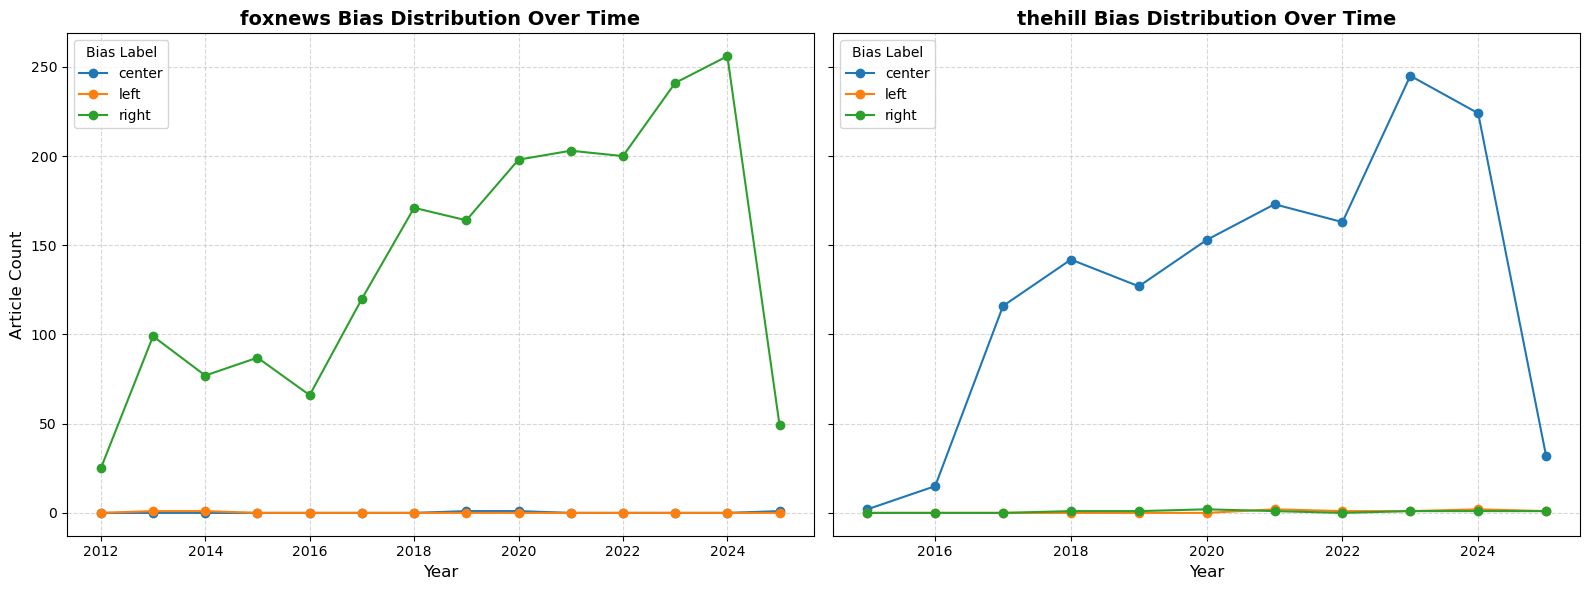

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data Preparation ---

# Select the top 2 sources by article count (or adjust this number as needed)
selected_sources = df['source'].value_counts().head(2).index.tolist()

# Group the data by year, source, and position and count the articles
df_source_year = df[df['source'].isin(selected_sources)]\
    .groupby(['year', 'source', 'position']).size().reset_index(name='Count')

# --- Plotting ---

# Create subplots: one subplot per selected source
fig, axes = plt.subplots(nrows=1, ncols=len(selected_sources), figsize=(16, 6), sharey=True)

# Loop over each selected source and plot its bias distribution over time
for i, source in enumerate(selected_sources):
    # Filter data for the current source
    source_data = df_source_year[df_source_year['source'] == source]
    # Pivot the data: rows = year, columns = position, values = Count
    pivot_data = source_data.pivot(index='year', columns='position', values='Count').fillna(0)
    
    # Plot a line for each bias label
    pivot_data.plot(ax=axes[i], marker='o')
    axes[i].set_title(f"{source} Bias Distribution Over Time", fontsize=14, fontweight='bold')
    axes[i].set_xlabel("Year", fontsize=12)
    axes[i].set_ylabel("Article Count", fontsize=12)
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend(title="Bias Label", fontsize=10)

plt.tight_layout()
plt.show()

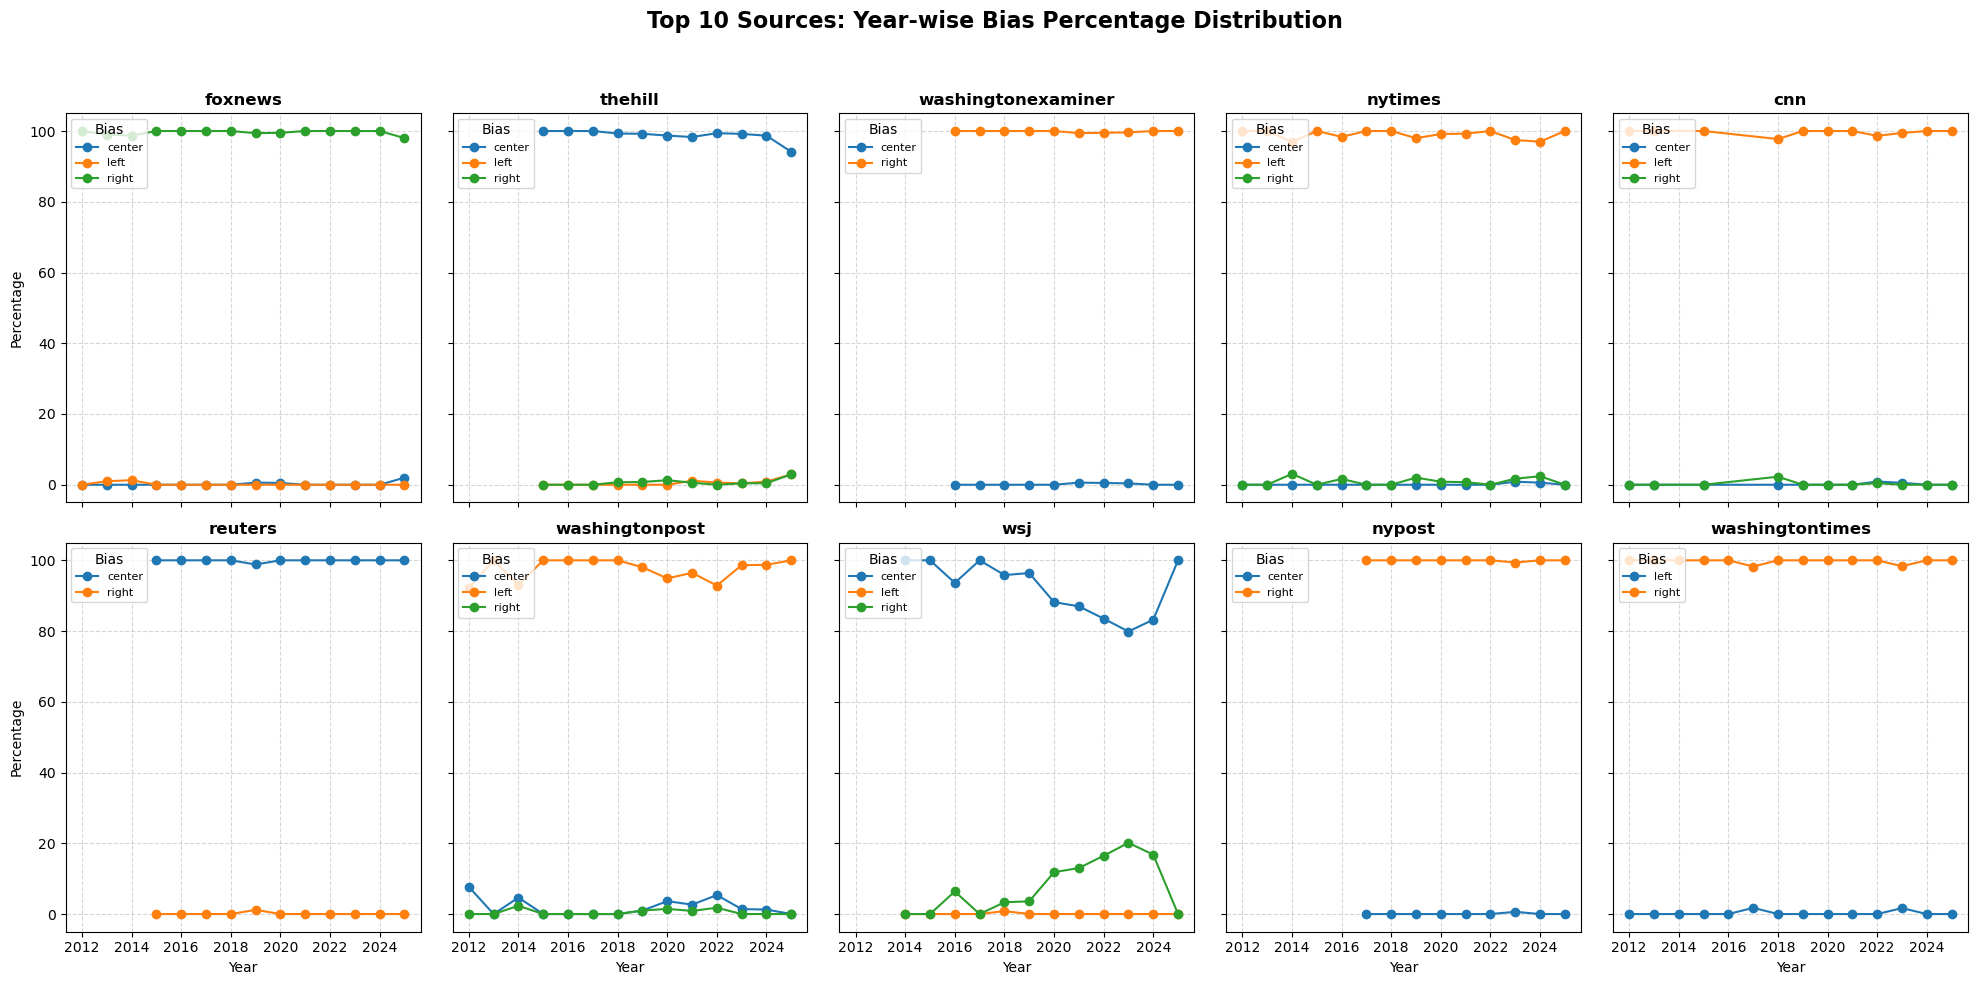

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Data Preparation ---

# 1. Get the top 10 sources by article count
top_10_sources_list = df['source'].value_counts().head(10).index.tolist()
df_top_sources = df[df['source'].isin(top_10_sources_list)]

# 2. Group by year, source, and position; count articles per group
grouped = df_top_sources.groupby(['year', 'source', 'position']).size().reset_index(name='Count')

# 3. Compute total articles per year and source
totals = df_top_sources.groupby(['year', 'source']).size().reset_index(name='Total')

# 4. Merge group counts with total counts and calculate percentage
grouped = pd.merge(grouped, totals, on=['year', 'source'], how='left')
grouped['Percentage'] = (grouped['Count'] / grouped['Total'] * 100).round(2)

# --- Plotting ---

# Create subplots: 2 rows x 5 columns for the top 10 sources
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten()

# Plot for each top source
for i, source in enumerate(top_10_sources_list):
    # Filter data for the current source
    source_data = grouped[grouped['source'] == source]
    # Pivot data: rows = year, columns = position, values = Percentage
    pivot_data = source_data.pivot(index='year', columns='position', values='Percentage').fillna(0)
    ax = axes[i]
    # Plot lines for each bias label
    pivot_data.plot(ax=ax, marker='o')
    ax.set_title(source, fontsize=12, fontweight='bold')
    ax.set_xlabel("Year", fontsize=10)
    ax.set_ylabel("Percentage", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(title="Bias", fontsize=8, loc='upper left')

# Remove any unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Top 10 Sources: Year-wise Bias Percentage Distribution", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [20]:
# Total number of articles in the dataset
total_articles = len(df)

# ------------------------------
# Topics Analysis (More than 100 Articles)
# ------------------------------
topic_counts = df['topic'].value_counts()
topics_over_100 = topic_counts[topic_counts > 100].reset_index()
topics_over_100.columns = ['Topic', 'Count']
topics_over_100['Percentage'] = topics_over_100['Count'] / total_articles * 100

# Calculate average count among topics with >100 articles
mean_topic_count = topics_over_100['Count'].mean()
topics_over_100['Times Average'] = topics_over_100['Count'] / mean_topic_count

print("Topics with more than 100 articles:")
print(topics_over_100)

# ------------------------------
# Sources Analysis (More than 100 Articles)
# ------------------------------
source_counts = df['source'].value_counts()
sources_over_100 = source_counts[source_counts > 100].reset_index()
sources_over_100.columns = ['Source', 'Count']
sources_over_100['Percentage'] = sources_over_100['Count'] / total_articles * 100

# Calculate average count among sources with >100 articles
mean_source_count = sources_over_100['Count'].mean()
sources_over_100['Times Average'] = sources_over_100['Count'] / mean_source_count

print("\nSources with more than 100 articles:")
print(sources_over_100)

Topics with more than 100 articles:
                            Topic  Count  Percentage  Times Average
0                        politics   2136    8.720147       5.278962
1                       elections   1809    7.385181       4.470806
2                economy and jobs   1325    5.409267       3.274637
3                     coronavirus   1136    4.637681       2.807538
4                           world   1096    4.474383       2.708681
5                     middle east    986    4.025311       2.436824
6                    donald trump    847    3.457849       2.093296
7                     immigration    842    3.437436       2.080939
8      2024 presidential election    820    3.347622       2.026568
9                     white house    677    2.763829       1.673154
10                  supreme court    616    2.514799       1.522397
11            violence in america    585    2.388242       1.445783
12                      joe biden    540    2.204532       1.334569
13          

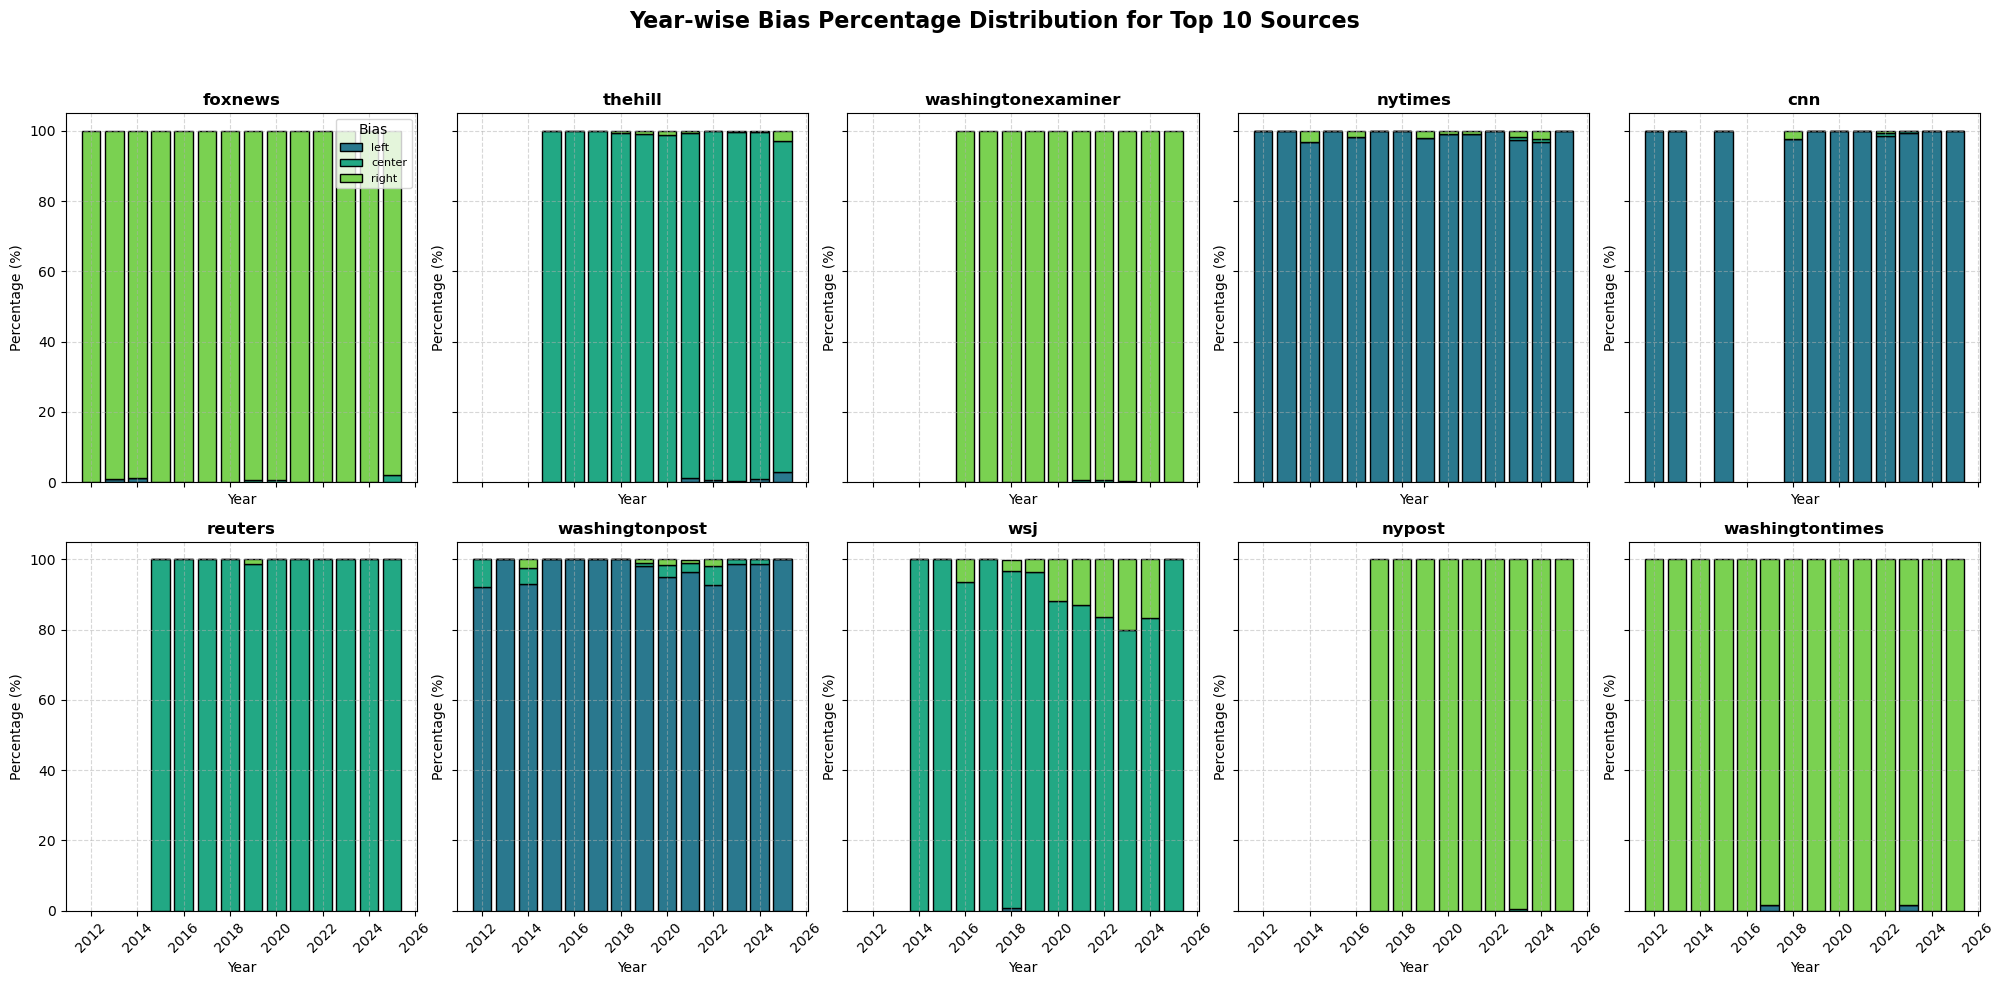

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Data Preparation ---

# Select top 10 sources by article count
top_10_sources_list = df['source'].value_counts().head(10).index.tolist()

# Group data by year, source, and position; count articles per group
grouped = (
    df[df['source'].isin(top_10_sources_list)]
    .groupby(['year', 'source', 'position'])
    .size()
    .reset_index(name='Count')
)

# Calculate total articles per year and source
totals = grouped.groupby(['year', 'source'])['Count'].sum().reset_index(name='Total')
grouped = pd.merge(grouped, totals, on=['year', 'source'])
grouped['Percentage'] = (grouped['Count'] / grouped['Total'] * 100).round(2)

# --- Plotting: Stacked Bar Charts for Each Top Source ---
# Create a grid of subplots (2 rows x 5 columns for the top 10 sources)
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten()

# Define consistent colors for bias labels (using Viridis palette)
colors = {
    'left': sns.color_palette("viridis", 4)[1],
    'center': sns.color_palette("viridis", 4)[2],
    'right': sns.color_palette("viridis", 4)[3]
}

# Loop over each top source and create a stacked bar chart
for i, source in enumerate(top_10_sources_list):
    ax = axes[i]
    # Filter data for the current source
    source_data = grouped[grouped['source'] == source]
    # Pivot the data: index = year, columns = bias label, values = Percentage
    pivot_data = source_data.pivot(index='year', columns='position', values='Percentage').fillna(0)
    
    # Optional: Enforce a specific column order if all three exist
    for pos in ['left', 'center', 'right']:
        if pos not in pivot_data.columns:
            pivot_data[pos] = 0
    pivot_data = pivot_data[['left', 'center', 'right']]
    
    # Plot stacked bar chart
    years = pivot_data.index
    bottom = pd.Series([0] * len(pivot_data), index=pivot_data.index)
    for pos in pivot_data.columns:
        ax.bar(years, pivot_data[pos], bottom=bottom, color=colors.get(pos, 'gray'),
               edgecolor='black', label=pos)
        bottom += pivot_data[pos]
    
    ax.set_title(source, fontsize=12, fontweight='bold')
    ax.set_xlabel("Year", fontsize=10)
    ax.set_ylabel("Percentage (%)", fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle="--", alpha=0.5)
    # Add legend only for the first subplot for clarity
    if i == 0:
        ax.legend(title="Bias", fontsize=8)
        
# Remove any extra subplots if present
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
fig.suptitle("Year-wise Bias Percentage Distribution for Top 10 Sources", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()